<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A05_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [3]:
# Імпортуйте необхідні бібліотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

In [14]:
# Завантажте датасет з Kaggle
from google.colab import files

uploaded = files.upload()

Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024 (1).csv


In [15]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv("kaggel_weather_2013_to_2024.csv")

display(df.head())

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

In [17]:
display(df.describe())

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


**Зміст**

Набір даних містить 3555 рядків з такими характеристиками:

**ДАТА** : Дата спостереження.

**Температура** : tempmax, tempmin, temp.

**Відчутна** **температура** : feelslikemax, feelslikemin, feelslike.

**Вологість** : Середня відносна вологість.

**Опади** : precip, precipprob, precipcover.

**Вітер і тиск** : windspeed, sealevelpressure.

**Умови** : Опис погоди (Ясно, Дощ, Хмарно тощо).

**Похідні** **показники** : temp_range, heat_index.

Підготовка даних

In [18]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
date_col = next(
    (col for col in df.columns if col.strip().upper() == "DATE"),
    None
)

if date_col is None:
    raise ValueError("Не знайдено стовпчик DATE. Перевірте назви стовпчиків.")

# Перетворення дати у формат datetime
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

# Видалення рядків, у яких дата відсутня або некоректна
df = df.dropna(subset=[date_col])

# Сортування за датою
df = df.sort_values(date_col)

# Видалення зайвих колонок, якщо вони є
extra_cols = [
    col for col in df.columns
    if col.strip().lower().startswith("unnamed")
]
df = df.drop(columns=extra_cols)

# Встановлення DATE як індексу
df = df.set_index(date_col)

In [19]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [20]:
# Перевірте наявність пропущених значень
print(df.isnull().sum())

tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64


In [21]:
print(df.isnull().sum().sum())

0


Графік температури

In [26]:
temp_col = "temp"

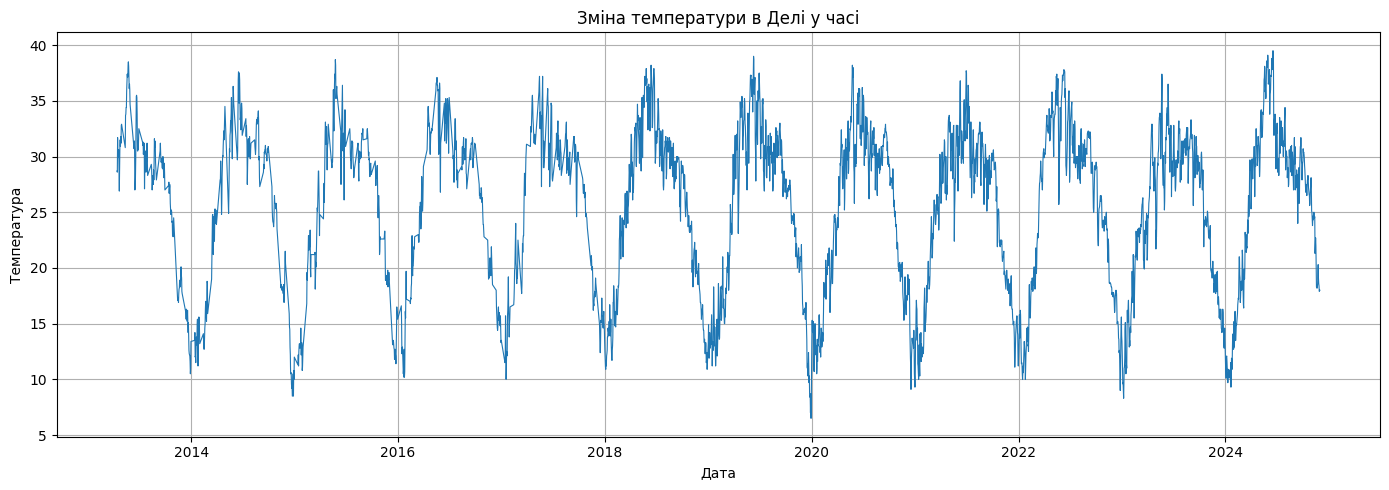

In [27]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))

plt.plot(df.index, df[temp_col], linewidth=0.8)

plt.title("Зміна температури в Делі у часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.grid(True)
plt.tight_layout()
plt.show()

Ковзне середнє

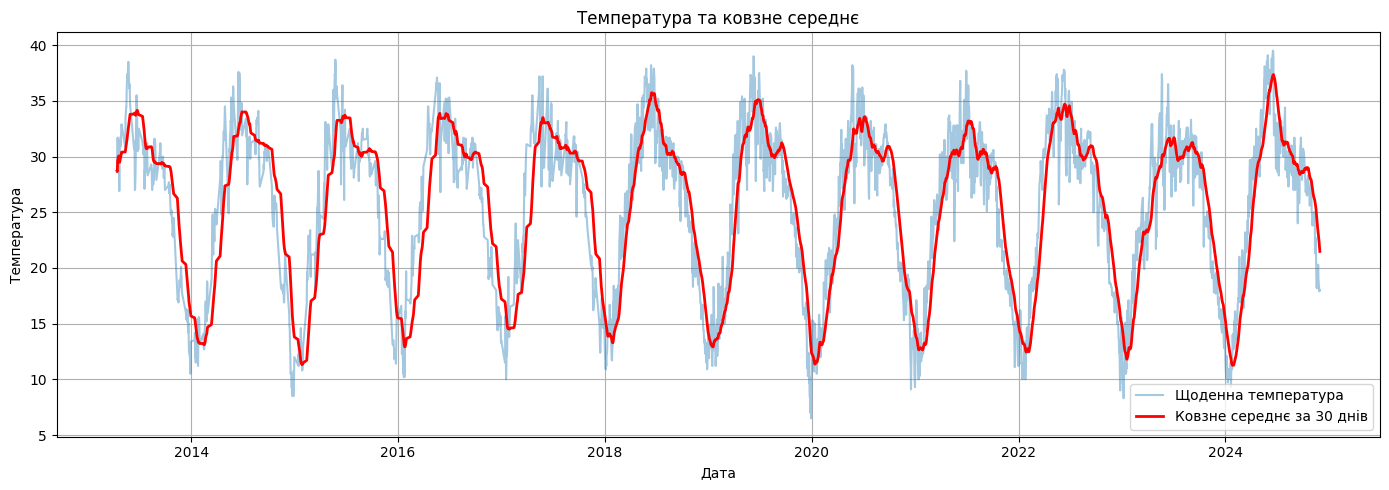

In [28]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["Rolling_Mean_30"] = df[temp_col].rolling(
    window=30,
    min_periods=1
).mean()

plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df[temp_col],
    alpha=0.4,
    label="Щоденна температура"
)

plt.plot(
    df.index,
    df["Rolling_Mean_30"],
    color="red",
    linewidth=2,
    label="Ковзне середнє за 30 днів"
)

plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Розподіл температури

Text(0.5, 0, 'Температура')

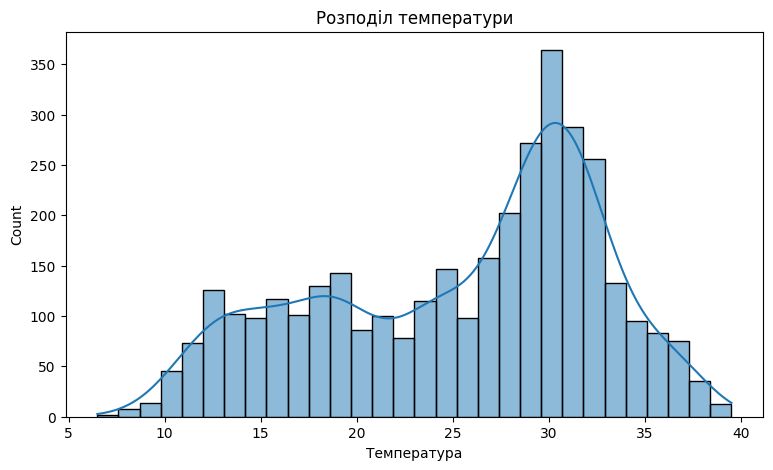

In [29]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(9, 5))

sns.histplot(df[temp_col].dropna(), bins=30, kde=True)

plt.title("Розподіл температури")
plt.xlabel("Температура")

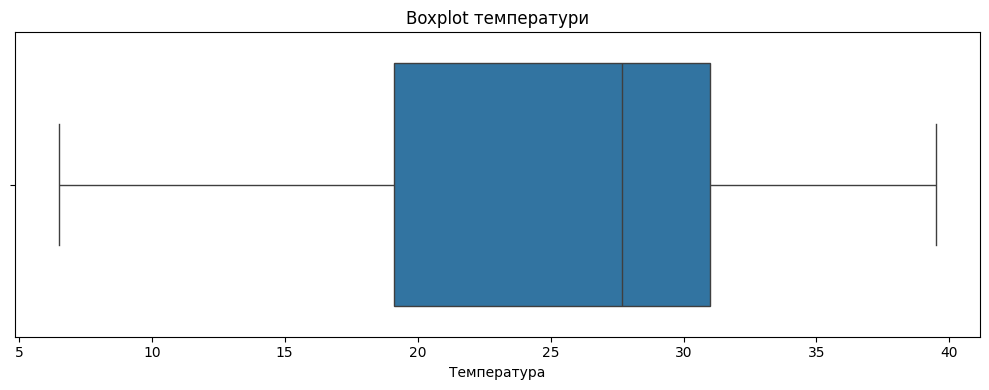

In [30]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))

sns.boxplot(x=df[temp_col])

plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.tight_layout()
plt.show()

Аналіз автокореляції
ACF

PACF

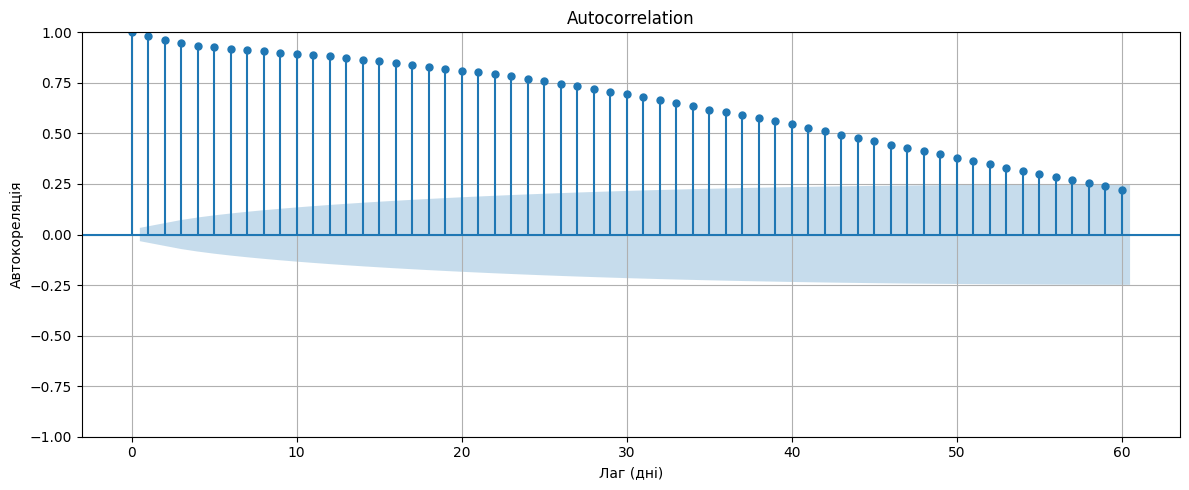

In [58]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Цільовий часовий ряд
ts = df["temp"].dropna()

plt.figure(figsize=(12, 5))
plot_acf(ts, lags=60, ax=plt.gca())
plt.xlabel("Лаг (дні)")
plt.ylabel("Автокореляція")
plt.grid(True)
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

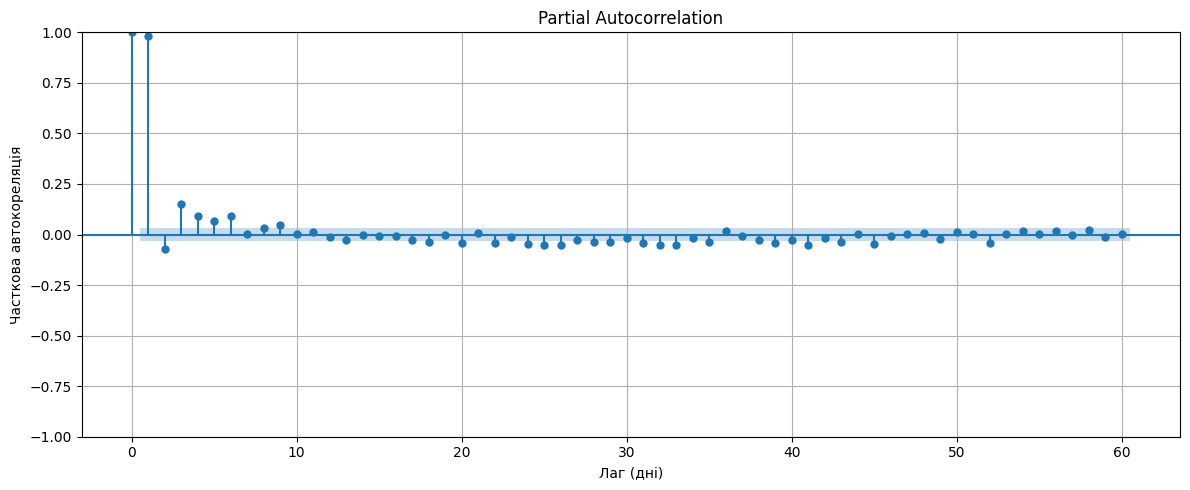

In [57]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 5))
plot_pacf(ts, lags=60, method="ywm", ax=plt.gca())
plt.xlabel("Лаг (дні)")
plt.ylabel("Часткова автокореляція")
plt.grid(True)
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [33]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target = df["temp"].copy()

# Межа поділу: 80% для навчання, 20% для тестування
split_index = int(len(target) * 0.8)

train = target.iloc[:split_index]
test = target.iloc[split_index:]

print("train size:", len(train))
print("Test size:", len(test))

train size: 2845
Test size: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [39]:
train_arima = train.reset_index(drop=True)

arima_model = ARIMA(train_arima, order=(5, 1, 2))
arima_fit = arima_model.fit()

arima_forecast_values = arima_fit.forecast(steps=len(test))

arima_forecast = pd.Series(
    arima_forecast_values.to_numpy(),
    index=test.index
)

In [40]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Thu, 22 Oct 2026   AIC                           9954.101
Time:                        09:56:12   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

In [43]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = mape(test, arima_forecast)

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape)

ARIMA MAE: 10.92780938078051
ARIMA RMSE: 12.500912027305812
ARIMA MAPE: 39.591987075351994


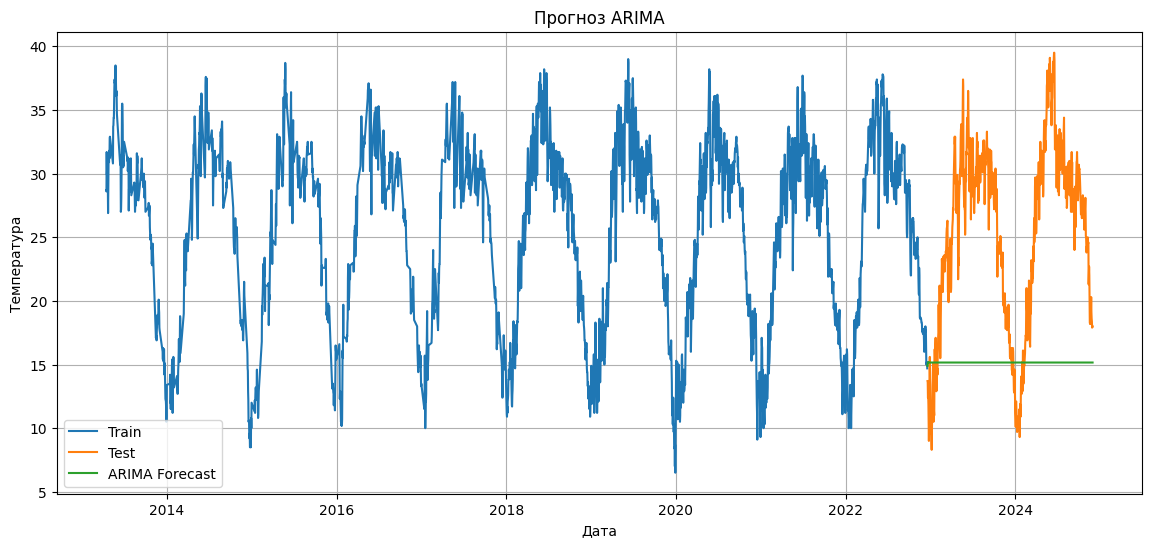

In [42]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.plot(arima_forecast.index, arima_forecast, label="ARIMA Forecast")
plt.title("Прогноз ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [45]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_df = df.reset_index()[["DATE", "temp"]]
prophet_df.columns = ["ds", "y"]

prophet_df["ds"] = pd.to_datetime(prophet_df["ds"])
prophet_df = prophet_df.dropna().sort_values("ds")

split_index = int(len(prophet_df) * 0.8)

prophet_train = prophet_df.iloc[:split_index]
prophet_test = prophet_df.iloc[split_index:]

In [46]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet()
prophet_model.fit(prophet_train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [49]:
# Прогноз для тестового періоду
future = prophet_test[["ds"]].copy()
prophet_prediction = prophet_model.predict(future)

prophet_forecast = prophet_prediction["yhat"].to_numpy()
y_true = prophet_test["y"].to_numpy()

In [50]:
# Обчисліть MAE, RMSE, MAPE для Prophet
def mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    return np.mean(
        np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    ) * 100

prophet_mae = mean_absolute_error(y_true, prophet_forecast)
prophet_rmse = np.sqrt(mean_squared_error(y_true, prophet_forecast))
prophet_mape = mape(y_true, prophet_forecast)

print("PROPHET MAE:", prophet_mae)
print("PROPHET RMSE:", prophet_rmse)
print("PROPHET MAPE:", prophet_mape)

PROPHET MAE: 2.004679994301011
PROPHET RMSE: 2.5901965298397274
PROPHET MAPE: 9.027934868552647


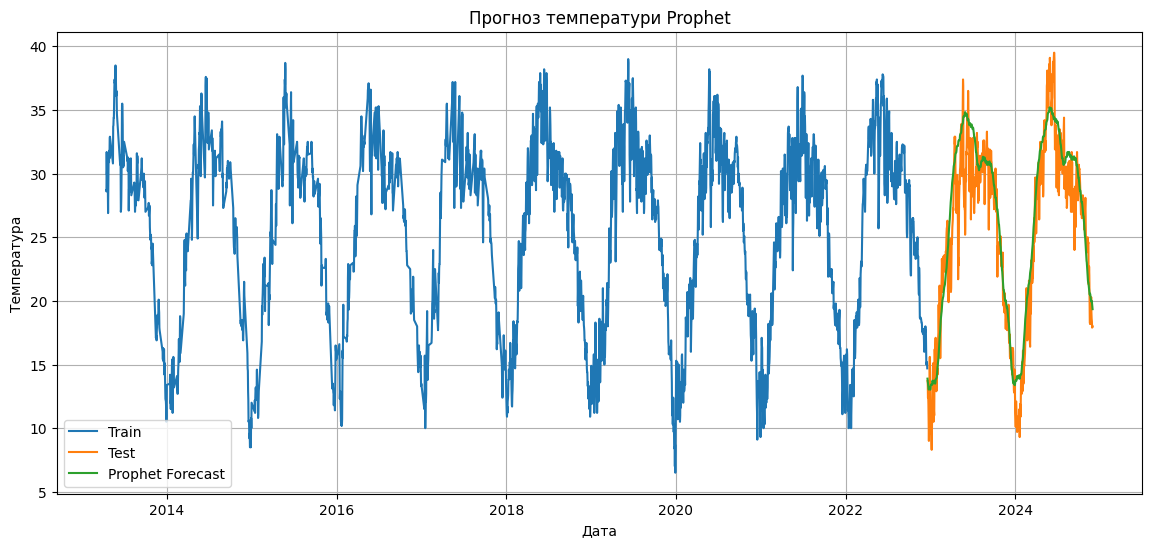

In [48]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))

plt.plot(prophet_train["ds"], prophet_train["y"], label="Train")

plt.plot(prophet_test["ds"], prophet_test["y"], label="Test")

plt.plot(prophet_test["ds"], prophet_forecast, label="Prophet Forecast")

plt.title("Прогноз температури Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

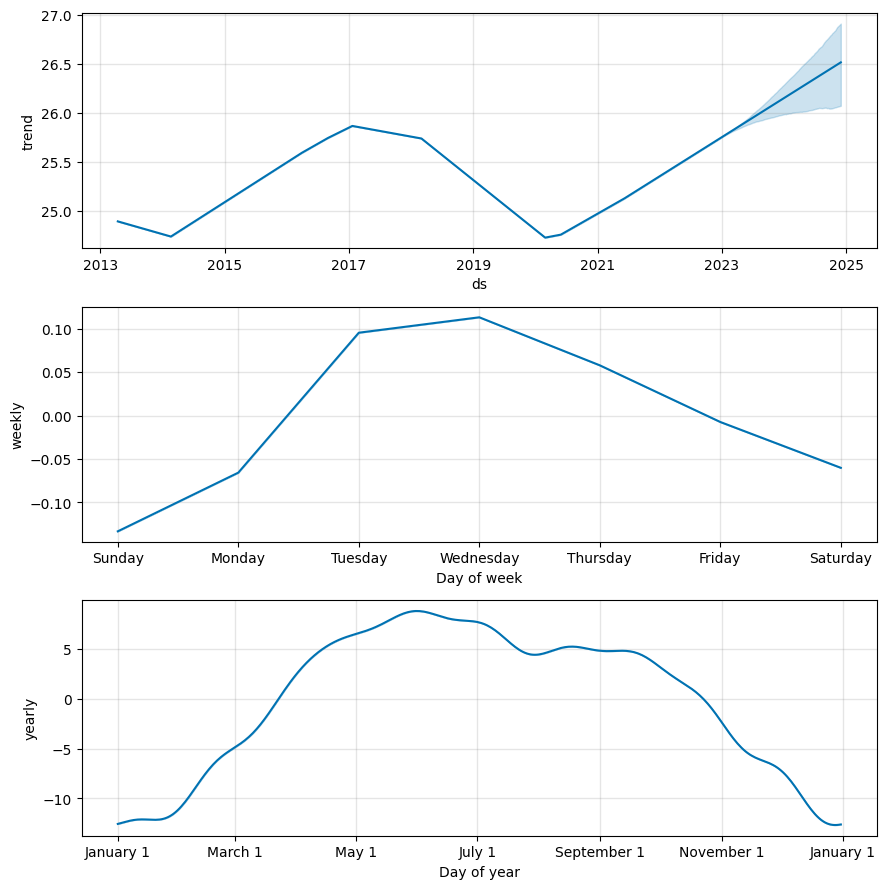

In [51]:
# Побудуйте компоненти моделі Prophet
prophet_model.plot_components(prophet_model.predict(prophet_df[["ds"]]))

plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [69]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df[["temp"]])

sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_values)):
    X.append(scaled_values[i-sequence_length:i, 0])
    y.append(scaled_values[i, 0])

X = np.array(X)
y = np.array(y)

X = X.reshape((X.shape[0], X.shape[1], 1))

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3527, 30, 1)
y shape: (3527,)


In [70]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
split_lstm = int(len(X) * 0.8)

X_train = X[:split_lstm]
X_test = X[split_lstm:]

y_train = y[:split_lstm]
y_test = y[split_lstm:]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2821, 30, 1)
X_test shape: (706, 30, 1)
y_train shape: (2821,)
y_test shape: (706,)


In [71]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential()
lstm_model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
lstm_model.add(LSTM(50))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer="adam", loss="mse")

In [72]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0238 - val_loss: 0.0053
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0056 - val_loss: 0.0047
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0052 - val_loss: 0.0045
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0049 - val_loss: 0.0038
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0047 - val_loss: 0.0036
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0043 - val_loss: 0.0034
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0040 - val_loss: 0.0030
Epoch 9/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0035 - val_loss: 0.0027
Epoch 10/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0031 - val_loss: 0.0034
Epoch 11/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0029 - val_loss: 0.0023
Epoch 12/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0025 - val_

In [73]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

In [74]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test)

# Повернення до початкового масштабу температури
lstm_forecast = scaler.inverse_transform(
    lstm_pred_scaled
).flatten()

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Прогноз отримано.")
print("Кількість прогнозованих значень:", len(lstm_forecast))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Прогноз отримано.
Кількість прогнозованих значень: 706


In [75]:
lstm_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [79]:
lstm_dates = df.index[sequence_length:][split_lstm:]

In [80]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(y_test_real, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_real, lstm_pred))
lstm_mape = mape(y_test_real, lstm_pred)

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)
print("LSTM MAPE:", lstm_mape)

LSTM MAE: 1.0276148477289562
LSTM RMSE: 1.3395539324553316
LSTM MAPE: 4.516356705254006


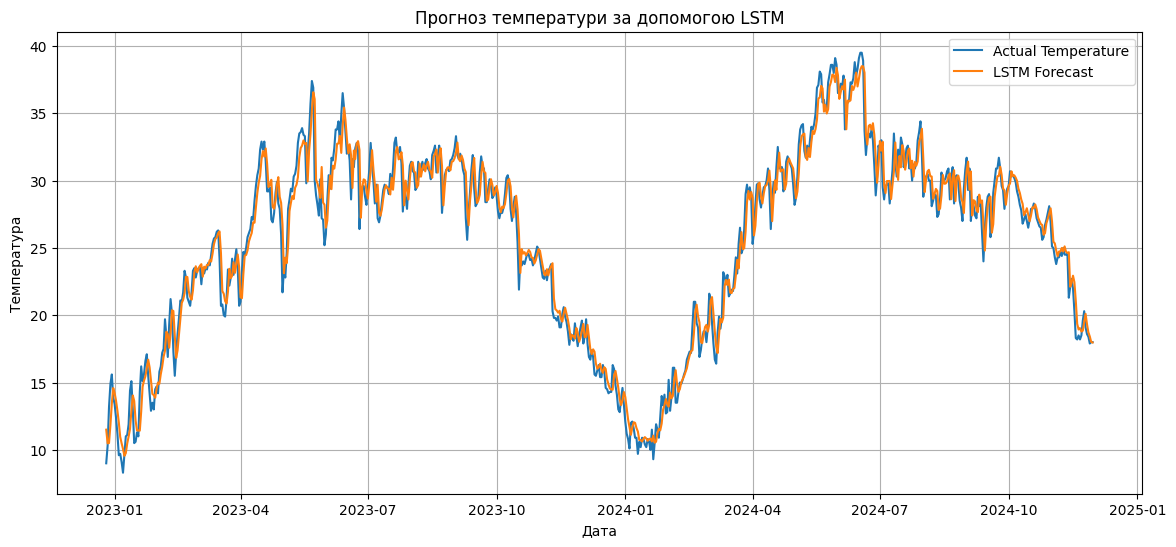

In [81]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(lstm_dates, y_test_real,label="Actual Temperature")
plt.plot(lstm_dates,lstm_pred,label="LSTM Forecast")
plt.title("Прогноз температури за допомогою LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [82]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "Model": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [arima_mae, prophet_mae, lstm_mae],
    "RMSE": [arima_rmse, prophet_rmse, lstm_rmse],
    "MAPE": [arima_mape, prophet_mape, lstm_mape]
})

print(results.sort_values("RMSE"))

     Model        MAE       RMSE       MAPE
2     LSTM   1.027615   1.339554   4.516357
1  Prophet   2.004680   2.590197   9.027935
0    ARIMA  10.927809  12.500912  39.591987


## Висновок

У ході роботи було побудовано та порівняно три моделі прогнозування температури: ARIMA, Prophet і LSTM. За результатами оцінювання найкращою виявилася модель LSTM, яка отримала найменші значення MAE (1,03), RMSE (1,34) та MAPE (4,52%). Модель Prophet показала середні результати, а ARIMA — найбільшу похибку прогнозування. Отже, для цього набору даних LSTM забезпечила найточніший прогноз температури, краще враховуючи закономірності часового ряду.
